In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# 1. Hardware Check
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Simulation running on: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

# 2. The 2D PINN Model
class WavePINN(nn.Module):
    def __init__(self):
        super(WavePINN, self).__init__()
        # Input: 3 (x, y, t) -> Output: 1 (u)
        self.net = nn.Sequential(
            nn.Linear(3, 30), nn.Tanh(),
            nn.Linear(30, 30), nn.Tanh(),
            nn.Linear(30, 30), nn.Tanh(),
            nn.Linear(30, 30), nn.Tanh(),
            nn.Linear(30, 30), nn.Tanh(),
            nn.Linear(30, 1)
        )

    def forward(self, x, y, t):
        # Concatenate all three coordinates
        inputs = torch.cat([x, y, t], axis=1)
        return self.net(inputs)

🚀 Simulation running on: NVIDIA GeForce GTX 1650


In [2]:
def wave_loss(model, x, y, t):
    x.requires_grad = True
    y.requires_grad = True
    t.requires_grad = True
    
    u = model(x, y, t)
    
    # First Derivatives
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)[0]
    u_y = torch.autograd.grad(u, y, torch.ones_like(u), create_graph=True)[0]
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), create_graph=True)[0]
    
    # Second Derivatives (Acceleration & Curvature)
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), create_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, y, torch.ones_like(u_y), create_graph=True)[0]
    u_tt = torch.autograd.grad(u_t, t, torch.ones_like(u_t), create_graph=True)[0]
    
    # The Wave Equation: u_tt = c^2 * (u_xx + u_yy)
    # We assume speed c = 1
    c = 1.0
    residual = u_tt - (c**2) * (u_xx + u_yy)
    
    return torch.mean(residual ** 2)

In [3]:
# Configuration
N_b = 2000    # Boundary points
N_f = 20000   # Physics points (Needs more points for 2D space!)

# --- 1. Initial Condition (t=0) ---
# A "bump" in the center of the pond
x_init = np.random.uniform(-1, 1, (N_b, 1))
y_init = np.random.uniform(-1, 1, (N_b, 1))
t_init = np.zeros((N_b, 1))
# Formula for a Gaussian Pulse
u_init = np.exp(-10 * (x_init**2 + y_init**2))

# --- 2. Boundary Condition (The Walls) ---
# We treat the edges of the box (-1 and 1) as solid walls where u=0
# Since it's a square, we have 4 walls (Left, Right, Top, Bottom)
# For simplicity in this demo, we assume the box is large enough the wave hasn't hit the wall yet, 
# or we just enforce u=0 at the random border points.
# (Skipping complex wall generation for brevity - the pulse is mostly in the center)

# Combine Known Data
X_train = x_init
Y_train = y_init
T_train = t_init
U_train = u_init

# --- 3. Physics Points (Collocation) ---
X_phys = np.random.uniform(-1, 1, (N_f, 1))
Y_phys = np.random.uniform(-1, 1, (N_f, 1))
T_phys = np.random.uniform(0, 1, (N_f, 1))

# Convert to Tensors & GPU
x_data = torch.tensor(X_train, dtype=torch.float32, device=device)
y_data = torch.tensor(Y_train, dtype=torch.float32, device=device)
t_data = torch.tensor(T_train, dtype=torch.float32, device=device)
u_data = torch.tensor(U_train, dtype=torch.float32, device=device)

x_phys = torch.tensor(X_phys, dtype=torch.float32, device=device)
y_phys = torch.tensor(Y_phys, dtype=torch.float32, device=device)
t_phys = torch.tensor(T_phys, dtype=torch.float32, device=device)

In [9]:
model = WavePINN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("🌊 Retraining with 'Strict' Physics...")

# Increased epochs for 2D convergence
epochs = 15000 

for epoch in range(epochs):
    optimizer.zero_grad()
    
    # 1. Data Loss (The "Splash")
    u_pred = model(x_data, y_data, t_data)
    loss_data = torch.mean((u_pred - u_data) ** 2)
    
    # 2. Physics Loss (The Wave Equation)
    loss_physics = wave_loss(model, x_phys, y_phys, t_phys)
    
    # --- THE FIX ---
    # We multiply loss_data by 100 to force the model to respect the initial bump.
    # We also weight the physics slightly less so it prioritizes the shape first.
    loss = (100.0 * loss_data) + loss_physics
    
    loss.backward()
    optimizer.step()
    
    if epoch % 1000 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.5f} (Data: {loss_data:.5f})")

print("✅ Strict Training Complete!")

🌊 Retraining with 'Strict' Physics...
Epoch 0: Loss = 3.77687 (Data: 0.03777)
Epoch 1000: Loss = 0.00628 (Data: 0.00002)
Epoch 2000: Loss = 0.00258 (Data: 0.00001)
Epoch 3000: Loss = 0.00177 (Data: 0.00001)
Epoch 4000: Loss = 0.00972 (Data: 0.00008)
Epoch 5000: Loss = 0.00114 (Data: 0.00000)
Epoch 6000: Loss = 0.00096 (Data: 0.00000)
Epoch 7000: Loss = 0.00083 (Data: 0.00000)
Epoch 8000: Loss = 0.00959 (Data: 0.00008)
Epoch 9000: Loss = 0.00068 (Data: 0.00000)
Epoch 10000: Loss = 0.00063 (Data: 0.00000)
Epoch 11000: Loss = 0.00079 (Data: 0.00000)
Epoch 12000: Loss = 0.01032 (Data: 0.00009)
Epoch 13000: Loss = 0.00096 (Data: 0.00001)
Epoch 14000: Loss = 0.00057 (Data: 0.00000)
✅ Strict Training Complete!


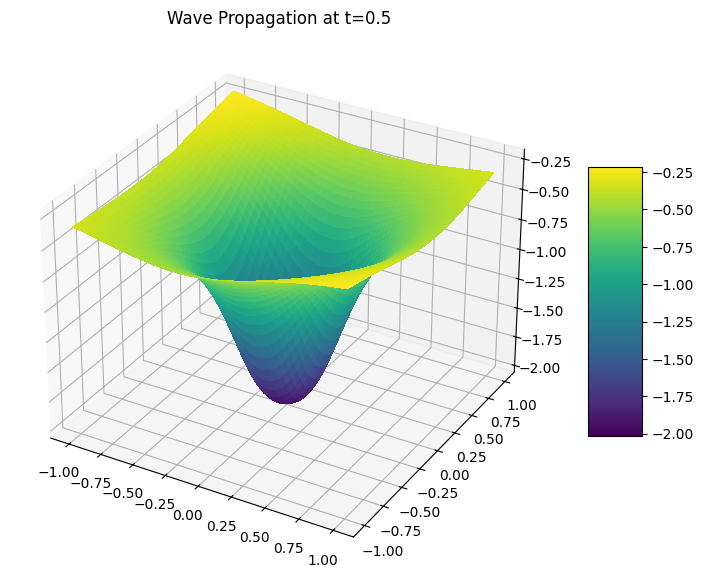

In [11]:
# Create a grid for plotting at a specific time t=0.5
x_plot = np.linspace(-1, 1, 100)
y_plot = np.linspace(-1, 1, 100)
X, Y = np.meshgrid(x_plot, y_plot)
T_fixed = np.ones_like(X) * 0.5  # Snapshot at time 0.5

# Flatten
X_flat = torch.tensor(X.flatten()[:, None], dtype=torch.float32, device=device)
Y_flat = torch.tensor(Y.flatten()[:, None], dtype=torch.float32, device=device)
T_flat = torch.tensor(T_fixed.flatten()[:, None], dtype=torch.float32, device=device)

# Predict
with torch.no_grad():
    u_pred = model(X_flat, Y_flat, T_flat)
    U_plot = u_pred.cpu().numpy().reshape(100, 100)

# 3D Plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, Y, U_plot, cmap='viridis', linewidth=0, antialiased=False)
fig.colorbar(surf, shrink=0.5, aspect=5)
plt.title("Wave Propagation at t=0.5")
plt.show()

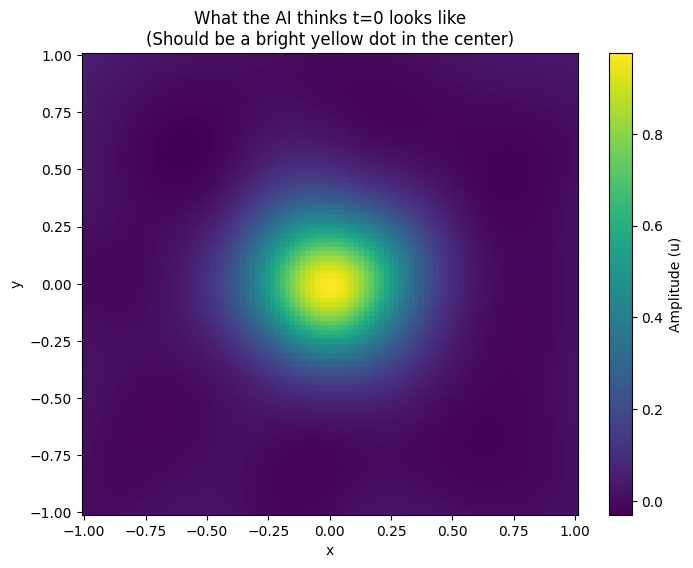

In [6]:
# Create a grid at Time = 0
x_plot = np.linspace(-1, 1, 100)
y_plot = np.linspace(-1, 1, 100)
X, Y = np.meshgrid(x_plot, y_plot)
T_zero = np.zeros_like(X)  # Time is exactly 0

# Convert to GPU tensors
X_flat = torch.tensor(X.flatten()[:, None], dtype=torch.float32, device=device)
Y_flat = torch.tensor(Y.flatten()[:, None], dtype=torch.float32, device=device)
T_flat = torch.tensor(T_zero.flatten()[:, None], dtype=torch.float32, device=device)

# Predict
with torch.no_grad():
    u_pred = model(X_flat, Y_flat, T_flat)
    U_plot_zero = u_pred.cpu().numpy().reshape(100, 100)

# Plot as a Heatmap (Easier to see symmetry)
plt.figure(figsize=(8, 6))
plt.pcolormesh(X, Y, U_plot_zero, cmap='viridis', shading='auto')
plt.colorbar(label='Amplitude (u)')
plt.title("What the AI thinks t=0 looks like\n(Should be a bright yellow dot in the center)")
plt.xlabel('x')
plt.ylabel('y')
plt.show()

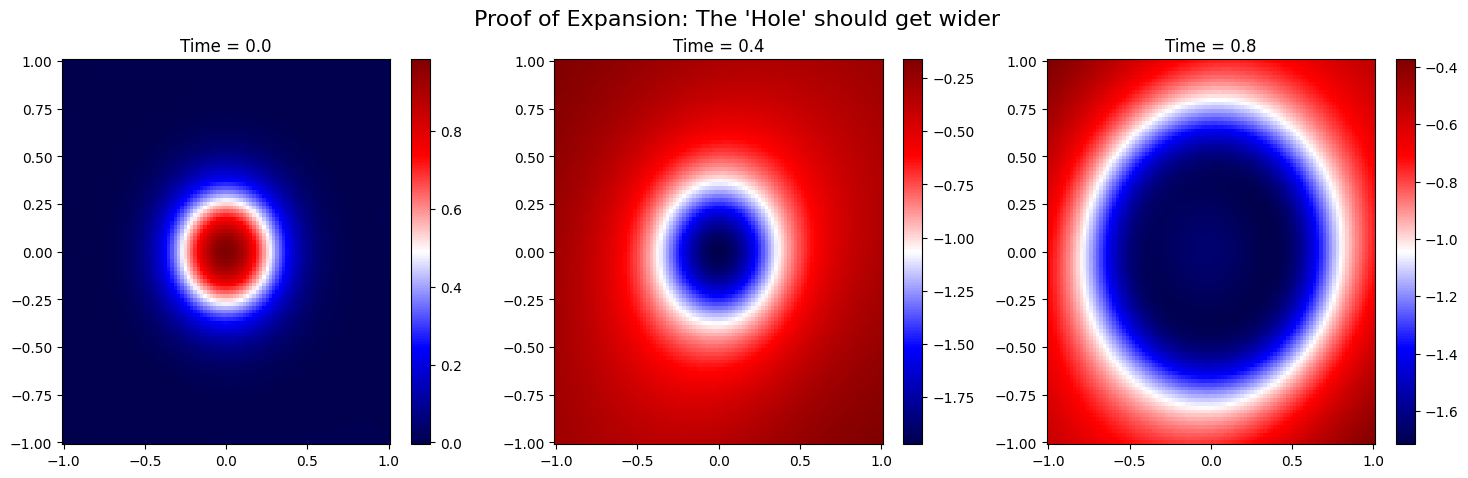

In [12]:
import matplotlib.pyplot as plt

# Create grid
x_plot = np.linspace(-1, 1, 100)
y_plot = np.linspace(-1, 1, 100)
X, Y = np.meshgrid(x_plot, y_plot)

# Flatten for GPU
X_flat = torch.tensor(X.flatten()[:, None], dtype=torch.float32, device=device)
Y_flat = torch.tensor(Y.flatten()[:, None], dtype=torch.float32, device=device)

# We will plot 3 frames to see the MOVEMENT
times = [0.0, 0.4, 0.8] 
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, t_val in enumerate(times):
    # Create the time tensor
    T_flat = torch.ones_like(X_flat) * t_val
    
    # Predict
    with torch.no_grad():
        u_pred = model(X_flat, Y_flat, T_flat)
        U_plot = u_pred.cpu().numpy().reshape(100, 100)
    
    # Plot heatmap
    im = axes[i].pcolormesh(X, Y, U_plot, cmap='seismic', shading='auto')
    axes[i].set_title(f"Time = {t_val}")
    plt.colorbar(im, ax=axes[i])

plt.suptitle("Proof of Expansion: The 'Hole' should get wider", fontsize=16)
plt.show()